In [62]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from scipy.stats import spearmanr
sns.set_style("whitegrid")


# ¿ De qué va este EDA?
Spotify obtiene indicadores mediante algoritmos de análisis de audio que procesan las características acústicas de cada canción, como el ritmo, la intensidad, el tempo, la estructura sonora y las propiedades espectrales. A partir de estos parámetros, sus modelos estiman diferentes atributos musicales y los transforman en valores normalizados entre 0 y 1. Estos valores no proceden de votaciones de los usuarios ni de valoraciones subjetivas, sino de modelos computacionales desarrollados por Spotify. Cada indicador mide una dimensión diferente: por ejemplo, Energy estima la intensidad y actividad percibida, Danceability la adecuación rítmica para bailar y Valence el carácter emocional positivo o negativo de la música.

Basdonos en ellos  vamos analizar un CSV con 15.000 hits. Analizaremos la evolución de la música en clave sociohistórica, haciendo un mix entre ciencia de datos y estudios culturales.

Nuestro CVS tiene 15000 registros, que empiezan con hits desde 1923. Sin embargo tras actor el marco temporal(1970-2015) nos quedamos en algo más de 10.000.

| Variable         | Rango habitual    | Significado                                       |
| ---------------- | ----------------- | ------------------------------------------------- |
| Danceability     | 0 – 1             | Facilidad para bailar.                            |
| Energy           | 0 – 1             | Intensidad y actividad de la canción.             |
| Loudness         | -60 – 0 dB aprox. | Volumen percibido de la grabación.                |
| Speechiness      | 0 – 1             | Presencia de palabras habladas.                   |
| Acousticness     | 0 – 1             | Probabilidad de que sea acústica.                 |
| Instrumentalness | 0 – 1             | Probabilidad de que no tenga voces.               |
| Liveness         | 0 – 1             | Probabilidad de que sea una grabación en directo. |
| Valence          | 0 – 1             | Positividad emocional percibida.                  |
| Tempo            | BPM               | Velocidad de la canción.                          |
| Duration         | Milisegundos      | Duración original de la canción.                  



# Tratamiento de los datos
El tratamiento de los datos requiere muy pocos cambios. En primer lugar, eliminamos todas las observaciones correspondientes a años que quedan fuera del periodo de estudio.

En segundo lugar, creamos una nueva variable categórica que agrupa los años en diferentes intervalos temporales, con el objetivo de facilitar el análisis y la comparación entre periodos.

También creamos la variable Genre2, en la que fusionamos los géneros Pop y Today. Esta decisión se basa en que las canciones clasificadas como Pop corresponden a años anteriores a 2000, mientras que las clasificadas como Today comienzan en 2002. Por tanto, entendemos que Today representa una continuación del género Pop. Asimismo, mantenemos el género Metal como una categoría independiente, ya que ambos géneros (Pop y Metal) son los que cuentan con un mayor número de registros. El resto de los géneros se agrupan en una única categoría denominada Resto de géneros.

De manera similar, creamos la variable Genre3, con el objetivo de aislar el género Country y facilitar su análisis específico.

Por último, multiplicamos por 100 las variables obtenidas a través de la API de Spotify, con el fin de facilitar su interpretación y mejorar la legibilidad de los resultados.

## Variables del dataset tras la limpieza

### Información general

- **Número de registros:** 10.104
- **Número de variables:** 21

### Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Track` | str | Nombre de la canción |
| `Artist` | str | Artista |
| `Year` | int64 | Año de lanzamiento |
| `Duration` | float64 | Duración de la canción |
| `Time_Signature` | int64 | Compás musical |
| `Danceability` | float64 | Facilidad para bailar |
| `Energy` | float64 | Intensidad y energía de la canción |
| `Key` | int64 | Tonalidad musical |
| `Loudness` | float64 | Volumen medio en decibelios |
| `Mode` | int64 | Modalidad musical (mayor o menor) |
| `Speechiness` | float64 | Presencia de palabras habladas |
| `Acousticness` | float64 | Grado de carácter acústico |
| `Instrumentalness` | float64 | Presencia de contenido instrumental |
| `Liveness` | float64 | Probabilidad de que sea una grabación en directo |
| `Valence` | float64 | Positividad emocional de la canción |
| `Tempo` | float64 | Velocidad musical en BPM |
| `Popularity` | int64 | Popularidad de la canción |
| `Genre` | str | Género musical |
| `Yearcat` | category | Clasificación categórica del año |
| `Genre2` | str | Segunda clasificación del género |
| `Genre3` | str | Tercera clasificación del género |

### Conclusión

El dataset resultante presenta una estructura de 10.104 observaciones y 21 variables, sin valores ausentes. Incluye información sobre canciones y artistas, características musicales, popularidad, año de lanzamiento y clasificación por géneros musicales.

Esta estructura permite realizar análisis exploratorios y estudiar posibles relaciones entre las características musicales, la popularidad y la evolución de los géneros a lo largo del tiempo.

In [63]:
#Cargar datos
df = pd.read_csv("ClassicHit.csv")
df = df[df["Year"] > 1970]
df = df[df["Year"] < 2015]

df["Yearcat"] = pd.cut(
    df["Year"],
    bins=[1969, 1979, 1989, 1999, 2015],
    labels=["1970-1979", "1980-1989", "1990-1999", "2000-2015"]
)
df["Genre2"] = np.select(
    [
        df["Genre"] == "Metal",
        df["Genre"].isin(["Pop", "Today"]),        
    ],
    [
        "Metal",
        "Pop/Today",
    ],
    default="Resto de géneros"
)
df["Duration"] = (df["Duration"]/1000) /60


df["Valence"] = df["Valence"] *100
df["Energy"] = df["Energy"] *100
df["Danceability"] = df["Danceability"] *100
df["Speechiness"] = df["Speechiness"] *100
df["Acousticness"] = df["Acousticness"] *100
df["Instrumentalness"] = df["Instrumentalness"] *100
df["Liveness"] = df["Liveness"] *100



medianas1 = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas2 = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas3 = df.groupby("Time_Signature")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas4 = df.groupby("Genre")[["Mode"]].mean()

variablesmat = ["Year","Loudness","Valence","Energy","Acousticness","Danceability","Tempo","Instrumentalness","Speechiness","Popularity"]
corr = df[variablesmat].corr("spearman")

df["Genre3"] = np.select(
    [
        df["Genre"] == "Country"


    
    ],
    [
        "Country"
      

    ],
    default="Resto de géneros"
)

df.info()

<class 'pandas.DataFrame'>
Index: 10104 entries, 0 to 15149
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Track             10104 non-null  str     
 1   Artist            10104 non-null  str     
 2   Year              10104 non-null  int64   
 3   Duration          10104 non-null  float64 
 4   Time_Signature    10104 non-null  int64   
 5   Danceability      10104 non-null  float64 
 6   Energy            10104 non-null  float64 
 7   Key               10104 non-null  int64   
 8   Loudness          10104 non-null  float64 
 9   Mode              10104 non-null  int64   
 10  Speechiness       10104 non-null  float64 
 11  Acousticness      10104 non-null  float64 
 12  Instrumentalness  10104 non-null  float64 
 13  Liveness          10104 non-null  float64 
 14  Valence           10104 non-null  float64 
 15  Tempo             10104 non-null  float64 
 16  Popularity        10104 non-null  int6

# Hipótesis

### H1. La tonalidad y el modo de las canciones no afectan significativamente a los valores de los atributos musicales proporcionados por la API de Spotify.

### H2. El compás influye ligeramente en los valores de los atributos musicales proporcionados por la API de Spotify.

### H3. Entre 1975 y 2015, la música ha experimentado un aumento del volumen percibido (*loudness*).

### H4. Entre 1975 y 2015, la música ha experimentado una disminución de la positividad percibida (*valence*).

### H5. Entre 1975 y 2015, la música ha experimentado un aumento de la energía musical (*energy*).

### H6. Los cambios observados en el volumen, la positividad y la energía se manifiestan con mayor intensidad en el género Metal.

### H7. Algunos géneros musicales presentan evoluciones particulares a lo largo del tiempo que pueden contextualizarse en sus respectivos marcos sociopolíticos e históricos.

### H8. Los factores que determinan la popularidad de una canción varían en función del género musical.

# Primeros analísis descriptivos

Debido a que varias de las variables que vamos a analziar tienen valores outlier, vamos a trabajar con medianas.

El modo es un valor categorico de dos posiciones: 0 y 1. Vamos a utlizar la medias com el para estimar con imagianción metodologica como se distribuye. Esto lo haremos basandonos en la filosofía de la estadistica booleana.

In [64]:
### Funciones

def medianas(medianas,titulo):
    plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
    sns.heatmap(
        medianas,
        annot=True,
        cmap= "rocket_r",
        fmt='.2f',
        linewidths=0,
        vmin= 0,
        vmax=100,
        center=50
)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()
    return 

def mediasmodo(medianas):
    plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
    sns.heatmap(
        medianas,
        annot=True,
        cmap= "rocket_r",
        fmt='.2f',
        linewidths=0,
        vmin= 0,
        vmax=1,
        center=0.5
)
    plt.title("Medias de modo según género")
    plt.tight_layout()
    plt.show()

    return 

### variables

medianas1 = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas2 = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas3 = df.groupby("Time_Signature")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas4 = df.groupby("Genre")[["Mode"]].mean()
medianas5= df.groupby("Mode")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

Si observamos las medianas de los diferentes atributos según el género musical, podemos apreciar diferencias importantes entre ellos. En géneros como el EDM, el Gospel o el Metal, la mitad de las canciones presentan valores de *valence* inferiores a 40. Por el contrario, en géneros como el Disco, el Funk o el Ska, las medianas superan los 70 puntos, lo que refleja una mayor tendencia hacia valores elevados de positividad musical.

En cuanto a la energía (*energy*), géneros como el Metal, el Punk, el Ska y el Rock Alternativo destacan por presentar los valores más elevados. Por su parte, el Metal y el Punk se encuentran entre los géneros menos bailables, mientras que el Rap y el Reggae presentan los valores más altos de *danceability*.

Este primer análisis también permite observar que atributos como la verbalidad (*speechiness*) y la instrumentalidad (*instrumentalness*) presentan comportamientos muy condicionados por determinados géneros musicales. Por su parte, el atributo *liveness* muestra una variabilidad relativamente reducida. Por estos motivos, consideramos que estas tres variables tienen un interés comparativamente menor para el análisis posterior.

En cuanto a la tonalidad (*key*), se observa que su distribución presenta diferencias limitadas entre los distintos géneros musicales. Dado que esta variable parece aportar poca información discriminativa para los objetivos de nuestro análisis, hemos decidido no profundizar en la correspondencia entre sus valores numéricos y las respectivas notas musicales.

El compás (*time signature*), en cambio, presenta resultados más interesantes. Las canciones cuyo compás es 4 tienden a mostrar valores más elevados de *valence*, *energy* y *danceability*. Este valor corresponde al compás de 4/4, el más habitual en la música popular.

Por otro lado, aunque pueda resultar sorprendente, el modo (*mode*) no parece mostrar diferencias especialmente relevantes en las medianas de los principales atributos musicales.

No obstante, aunque el modo no es una variable numérica continua, está codificado de forma binaria: 0 corresponde al modo menor y 1 al modo mayor. Esta codificación permite calcular su media para cada género musical, obteniendo así una aproximación a la proporción de canciones que utilizan el modo mayor. Los resultados muestran que géneros como el Country, el Gospel o el Ska presentan una mayor tendencia a utilizarlo.

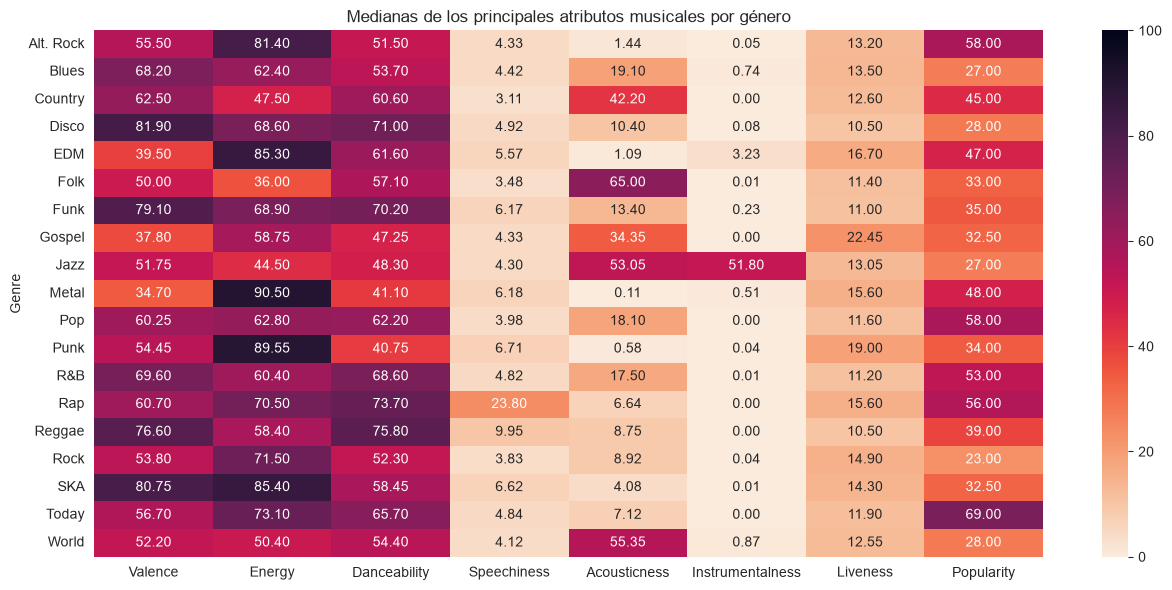

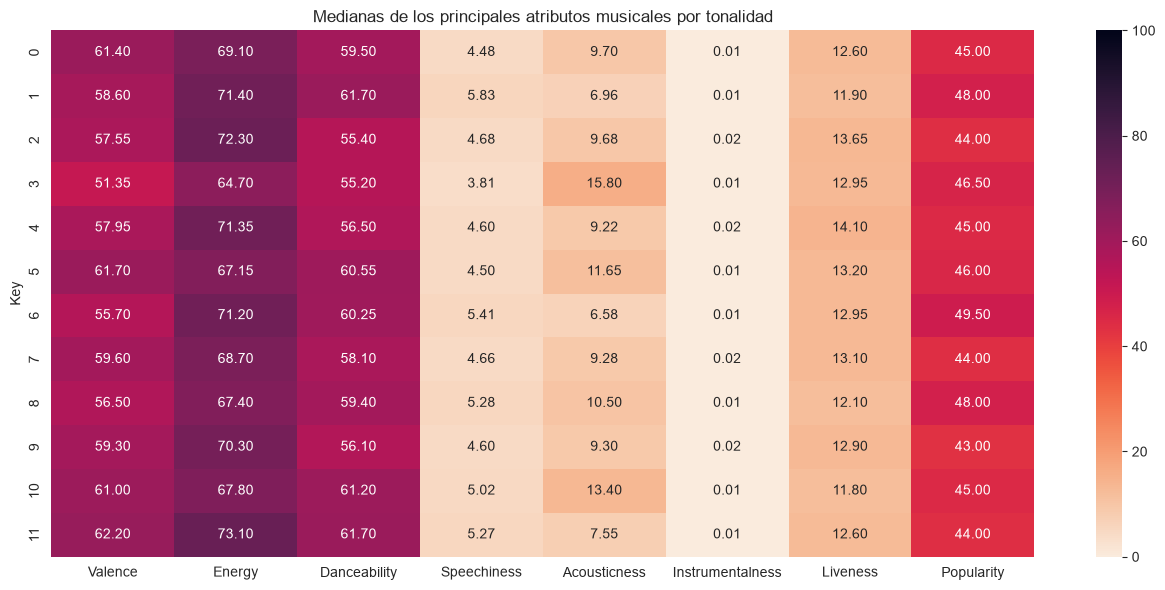

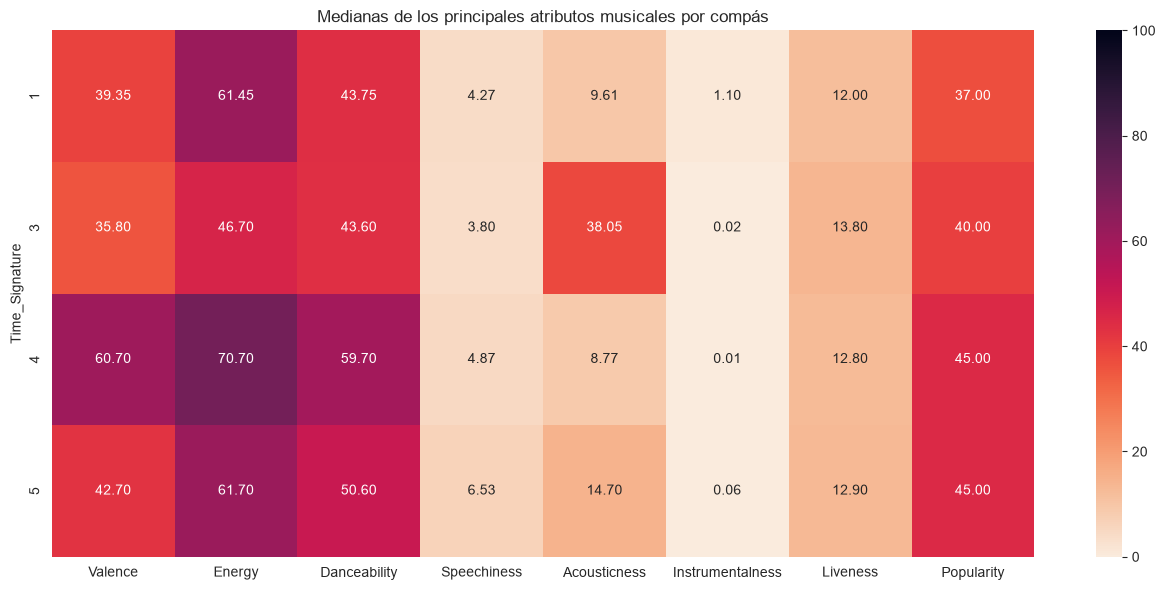

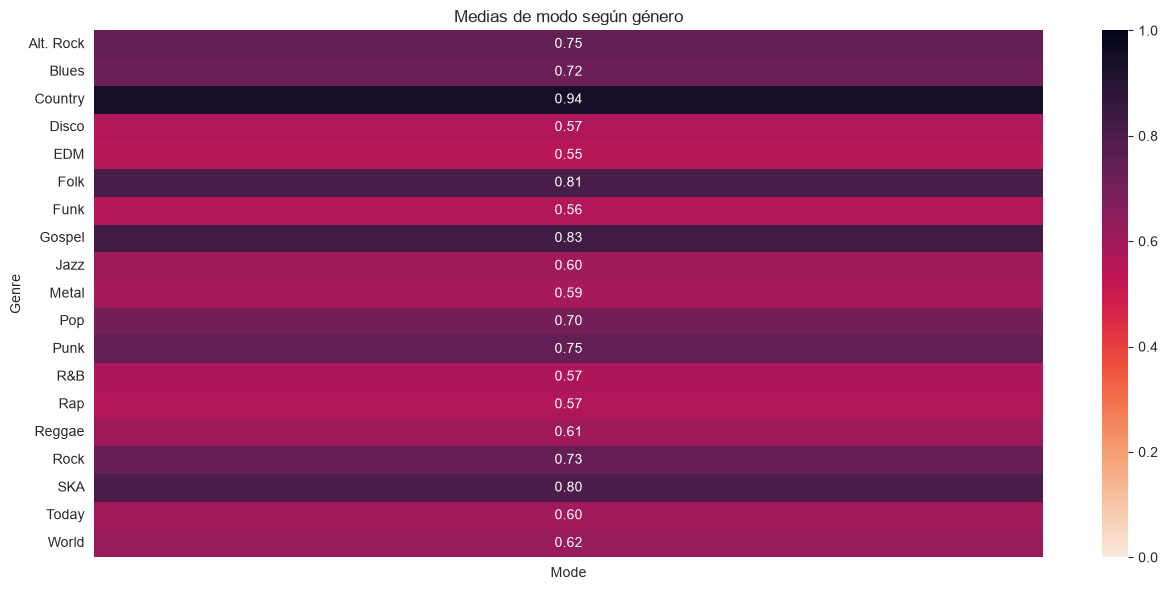

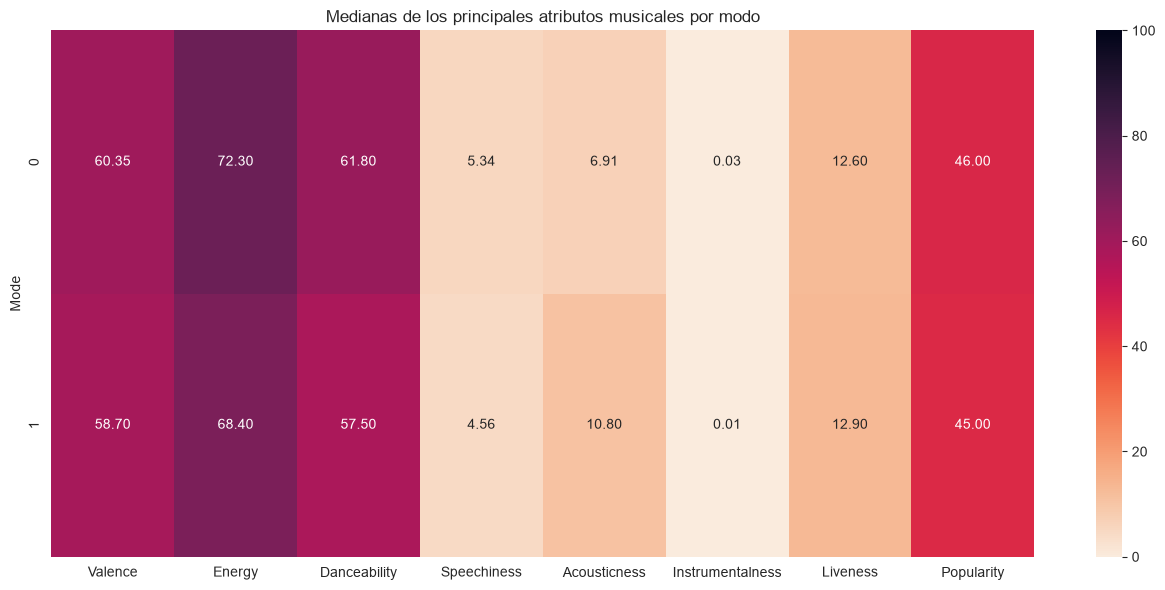

In [65]:
medianas(medianas1,"Medianas de los principales atributos musicales por género")
medianas(medianas2,"Medianas de los principales atributos musicales por tonalidad")
medianas(medianas3,"Medianas de los principales atributos musicales por compás")
mediasmodo(medianas4)
medianas(medianas5,"Medianas de los principales atributos musicales por modo")



# Matriz de correlaciones   

In [66]:
def matcorr(corr):
    

    plt.figure(figsize=(12, 5))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0,
        vmin =-1
    )

    plt.title("Matriz de correlaciones (Spearman) - Principales variables numéricas")
    plt.tight_layout()
    plt.show()
    return 
variablesmat = ["Year","Loudness","Valence","Energy","Acousticness","Danceability","Tempo","Instrumentalness","Speechiness","Popularity"]
corr = df[variablesmat].corr("spearman")

Podemos observar una correlación positiva notable entre el año de lanzamiento y el volumen (*loudness*). Además, la variable año también presenta una correlación positiva considerable con la energía (*energy*) y correlaciones negativas con la valencia (*valence*) y la acústica (*acousticness*).

En cuanto a la popularidad (*popularity*), las correlaciones son más débiles. Aun así, podemos destacar una relación positiva con el año de lanzamiento y el volumen, así como una correlación negativa con la instrumentalidad (*instrumentalness*).

Por último, también encontramos relaciones destacables entre otros atributos musicales. La acústica y la energía presentan una correlación negativa, mientras que el volumen y la energía muestran una correlación positiva. Asimismo, la valencia y la capacidad de baile (*danceability*) están positivamente correlacionadas.

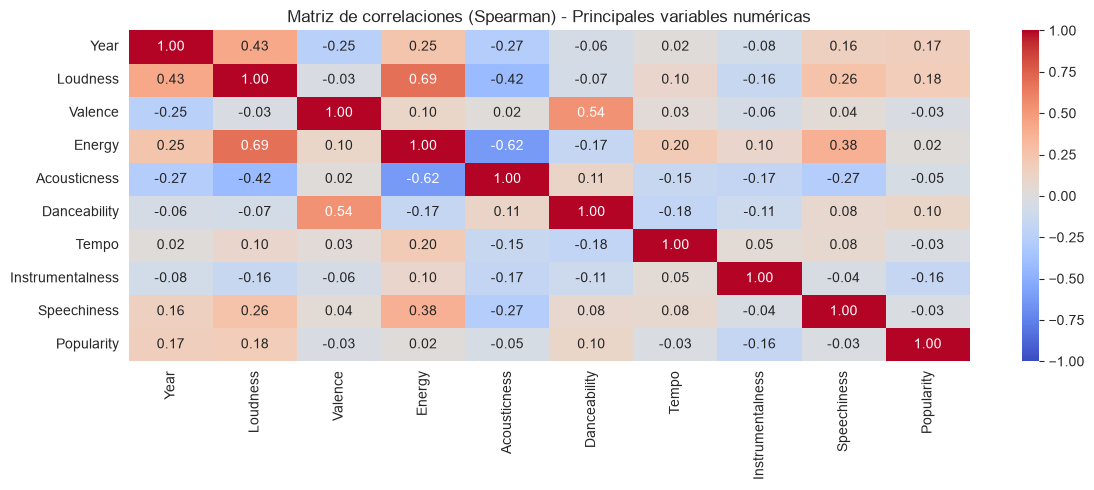

In [67]:

matcorr(corr)

# Evolución del volumen percivido

In [68]:
def graflin(df,y,titulo):
    plt.figure(figsize=(12,5))
    sns.lineplot(data = df, x = "Year" , y = y , hue = "Genre2", palette = "colorblind", estimator="mean", errorbar=("ci", 90))
    plt.title(titulo)
    plt.tight_layout()
    plt.show()
    return
def cajatemp(df, x,titulo):
    plt.figure(figsize=(12,5))

    sns.boxplot(data = df, x = x, y= "Genre2" , fill = True   ,hue = "Yearcat",showmeans=True,  meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 7,
            "alpha": 0.6
        }
    )
    plt.title(titulo)
    plt.legend(
        title="Rango temporal",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0
        )
    plt.show()
    return

def densi(df,x,titulo):
    #plt.style.use("dark_background")

    plt.figure(figsize=(12,5))

    sns.kdeplot(data= df,x = x, hue="Year", palette=  "viridis", legend=False, common_norm=False,alpha = 0.6)
    plt.title(titulo)
    plt.show()

    return

En el conjunto de todos los géneros, el volumen medio de las canciones pasa de situarse ligeramente por encima de los -12 dB en 1970 a acercarse a los -6 dB en 2015. Esto supone un incremento considerable del volumen percibido a lo largo del periodo analizado.

Se observa una tendencia similar tanto en el Metal como en el Pop/Today. El gráfico de líneas permite identificar que este crecimiento se concentra principalmente entre 1990 y mediados de la década de los 2000.

El gráfico de cajas permite profundizar en esta evolución y comparar la distribución del volumen entre las distintas décadas. Durante los años 70 y 80 se aprecian pocos cambios significativos. En la década de los 90, la mediana del volumen aumenta ligeramente en las tres categorías analizadas: Metal, conjunto de todos los géneros y Pop/Today.

Sin embargo, es a partir del año 2000 cuando se produce un salto especialmente pronunciado. La mediana del volumen en el periodo 2000-2025 se sitúa aproximadamente al nivel del percentil 75 de la década de los 90. En el caso del Metal, este fenómeno es todavía más intenso: el primer cuartil (percentil 25) del periodo 2000-2025 se encuentra prácticamente al mismo nivel que el tercer cuartil (percentil 75) de los años 90.

Otro aspecto destacable es que el extremo inferior de la distribución del periodo 2000-2025 alcanza valores de volumen percibido similares a la media de los años 90. Esto indica que el aumento no se limita a las canciones más ruidosas, sino que también afecta a las que presentan niveles de volumen más bajos.

Por último, el gráfico de densidad permite visualizar con mayor claridad cómo ha evolucionado la distribución del volumen a lo largo del tiempo, mostrando el desplazamiento progresivo de las curvas hacia valores menos negativos de *loudness*.


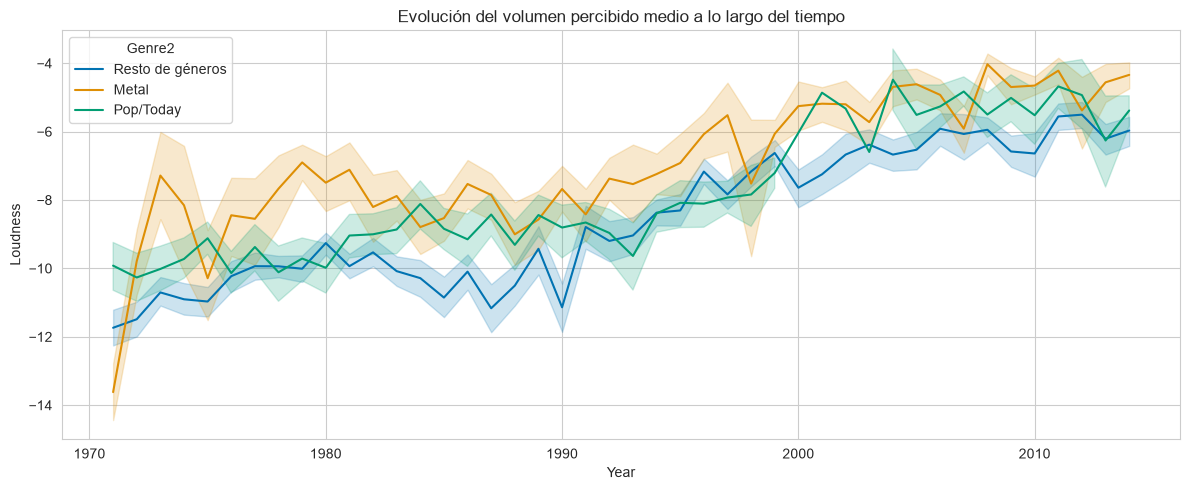

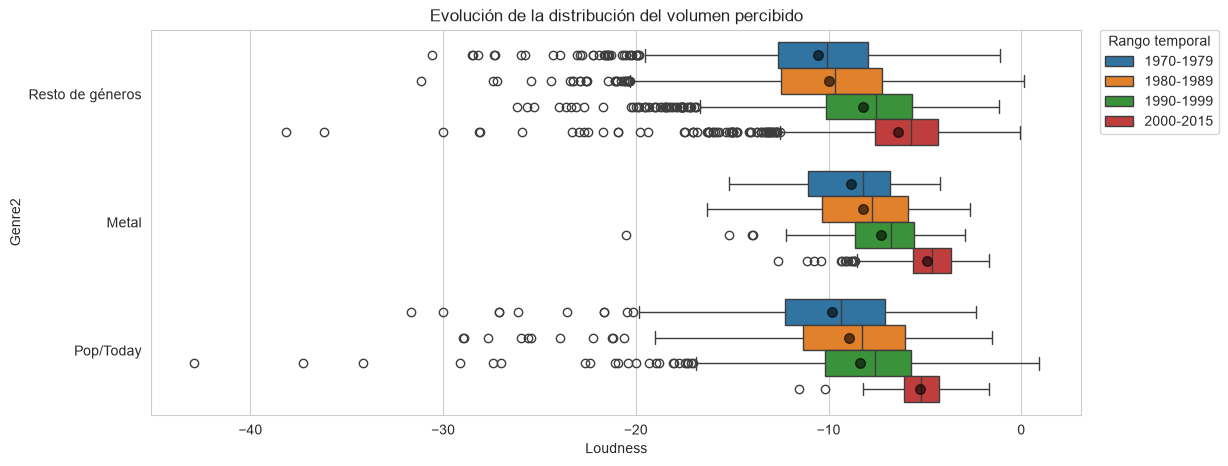

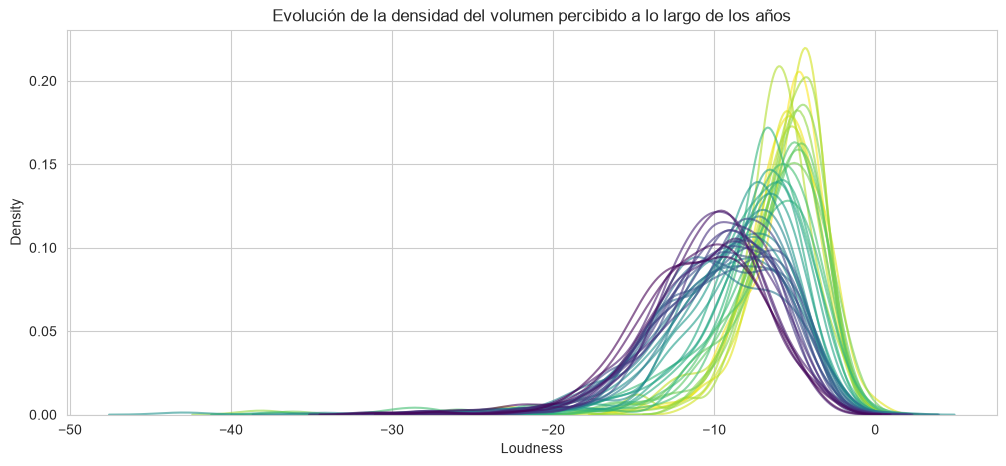

In [69]:
graflin(df,"Loudness","Evolución del volumen percibido medio a lo largo del tiempo")
cajatemp(df, "Loudness" ,"Evolución de la distribución del volumen percibido")
densi(df,"Loudness","Evolución de la densidad del volumen percibido a lo largo de los años")

# Evolución de la positividad

In [70]:
def graflin2(df):
    plt.figure(figsize=(12,5))

    sns.lineplot(
        data=df,
        x="Year",
        y="Valence",
        hue="Genre3",
        palette="colorblind",
        estimator="mean",
        errorbar=("ci", 90)
    )

    plt.xlim(1996, 2010)

    plt.title(
        "Evolución de la  positividad percibida por Spotify a lo largo de los años. "
        "Ciclo de guerra de Irak: Country vs resto de géneros"
    )

    plt.axvline(x=2001, color="red", linestyle="--", linewidth=0.5)
    plt.axhline(y=35, color="black", linestyle="--", linewidth=0.6)
    plt.axhline(y=76, color="black", linestyle="--", linewidth=0.6)

    plt.tight_layout()
    plt.show()
    return

    


A principios del periodo analizado, la media de positividad (*valence*) se sitúa en torno a los 65 puntos sobre 100 para el conjunto de los géneros musicales. Desde los años 80 hasta los 90 se observa un ligero descenso. Entre los años 90 y mediados de la década de los 2000, la media oscila entre los 50 y los 60 puntos. Sin embargo, hacia el final de esta década, el valor desciende hasta situarse entre los 40 y los 50 puntos.

En el caso del Pop, se observa una evolución similar a la del conjunto de los géneros. No obstante, tras la recategorización como Pop/Today, parece producirse una ligera recuperación de la métrica, acompañada de una mayor variabilidad en los valores.

Donde se aprecia una caída mucho más pronunciada es en el Metal. A principios de los años 70, los valores de este género no diferían demasiado de los del resto de estilos musicales. Sin embargo, durante las décadas de los 70 y los 80 se produce un descenso abrupto. En los 90, los valores se mantienen relativamente estables, pero durante el siglo XXI vuelven a caer.

Aunque a partir de 2010 se observan importantes fluctuaciones, posiblemente relacionadas con el menor número de canciones disponibles para cada año, hay un detalle que llama especialmente la atención: entre 2002 y 2005 se produce un ligero repunte de la positividad.

Este comportamiento despertó varias preguntas:

- ¿Qué estaba ocurriendo en Estados Unidos durante ese periodo?
- ¿Escuchaban Metal los militares estadounidenses?
- ¿Existía una relación entre el consumo de Metal y determinados sectores sociales, como los *rednecks*?
- ¿Había otros géneros musicales especialmente populares entre estos grupos?

A partir de estas preguntas, decidimos ampliar el análisis y estudiar la evolución del *valence* en el Country entre 1996 y 2010. Los resultados muestran que el valor medio más bajo se alcanza en 2001, con aproximadamente 35 puntos, mientras que el más alto se registra en 2005, con alrededor de 75 puntos.

Este resultado resulta llamativo. Mientras que la tendencia general de la música apuntaba hacia una pérdida progresiva de positividad, el Country experimentó un repunte especialmente acusado durante esos años. Esto abre una posible línea de investigación sobre el papel de determinados contextos sociales e históricos en la evolución emocional de algunos géneros musicales.

No obstante, estos datos no permiten afirmar que los consumidores de Country necesitaran un mayor estímulo moral ni que esa fuera la causa del cambio. Para sostener una interpretación de este tipo sería necesario contrastarla con fuentes históricas y sociológicas.

Hecho este inciso, volvamos a nuestras tres categorías: el conjunto del resto de géneros, el Metal y el Pop/Today.

El gráfico de cajas permite observar las variaciones que ya identificábamos en el gráfico de barras, pero desde otra perspectiva. En el conjunto de los géneros, la mediana del *valence* durante los años 70 se sitúa aproximadamente al nivel del percentil 75 de los años 80. En las décadas posteriores, las distribuciones siguen desplazándose hacia valores inferiores, aunque a un ritmo más lento. Finalmente, destaca que el percentil 75 de positividad del siglo XXI se sitúa aproximadamente al mismo nivel que el percentil 25 de los años 70.

En el caso del resto de géneros, el desplazamiento hacia valores inferiores de positividad es más uniforme entre décadas.

Por su parte, el Pop/Today presenta una particularidad: durante los años 70 y 80, sus canciones muestran valores de positividad ligeramente superiores a los del conjunto de los demás géneros.

Por último, el gráfico de densidad permite visualizar con claridad este fenómeno. Las curvas se desplazan progresivamente hacia la izquierda, lo que refleja una concentración cada vez mayor de canciones en valores inferiores de *valence*. En otras palabras, la distribución de la positividad musical evoluciona hacia valores progresivamente más bajos.

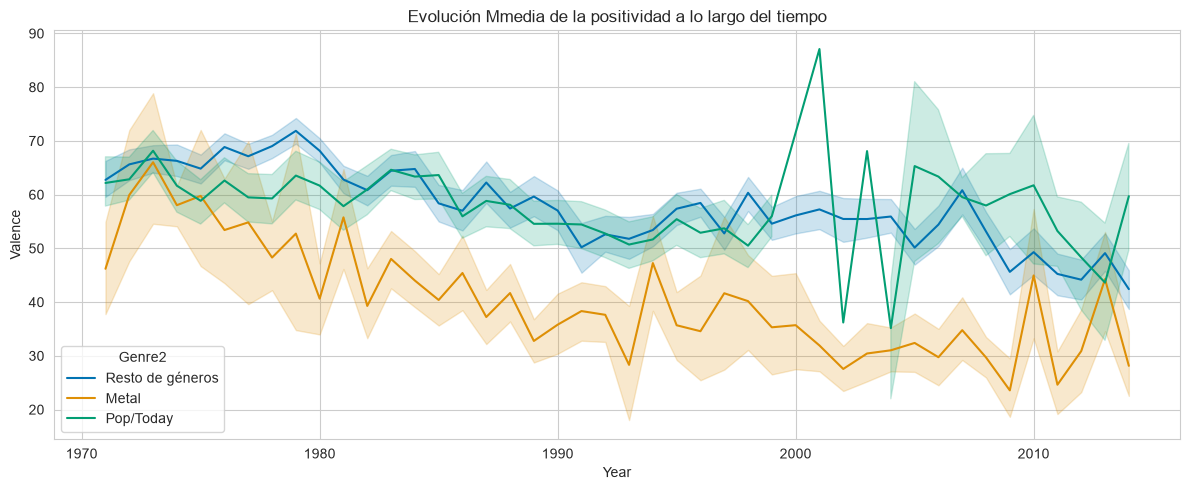

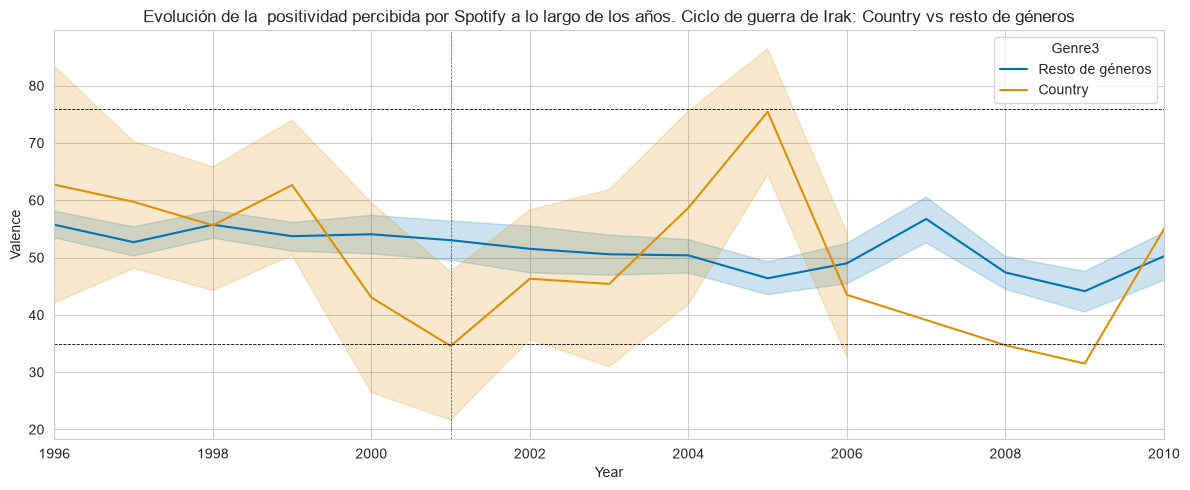

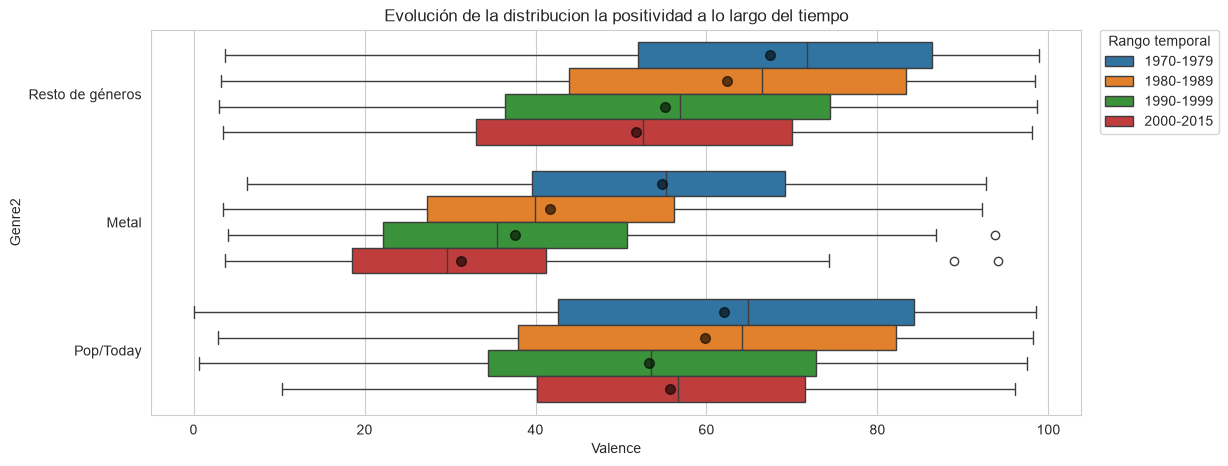

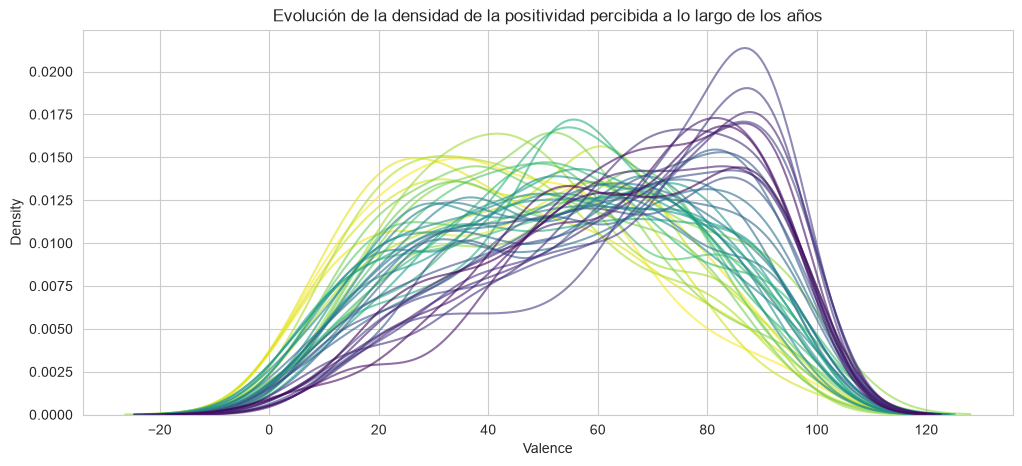

In [71]:
graflin(df,"Valence","Evolución Mmedia de la positividad a lo largo del tiempo")
graflin2(df)
cajatemp(df, "Valence", "Evolución de la distribucion la positividad a lo largo del tiempo")
densi(df,"Valence","Evolución de la densidad de la positividad percibida a lo largo de los años")

# Evolución de la energía

En 1970, la media de los tres grupos oscilaba entre el 50 y el 60.

El Metal experimenta un aumento brusco de energía y, desde los años ochenta, su media se sitúa en la franja comprendida entre el 80 y el 90. En el siglo XXI, llega a superar la barrera de los 90.

El resto de géneros y Pop/Música actual presentan una evolución más lenta, pero también ascendente. En el siglo XXI, ambos grupos alcanzan valores medios superiores a 70.

El gráfico de cajas aporta información adicional. En el caso del Metal, se observa un cambio notable en el siglo XXI: la mediana de este periodo supera el percentil 75 de las dos décadas anteriores. También se aprecia una mayor concentración de los valores en este siglo.

En Pop/Música actual también se observa un cambio sustancial durante el siglo XXI.

Por último, el gráfico de densidad muestra una mayor concentración de valores elevados al final del periodo que al principio.

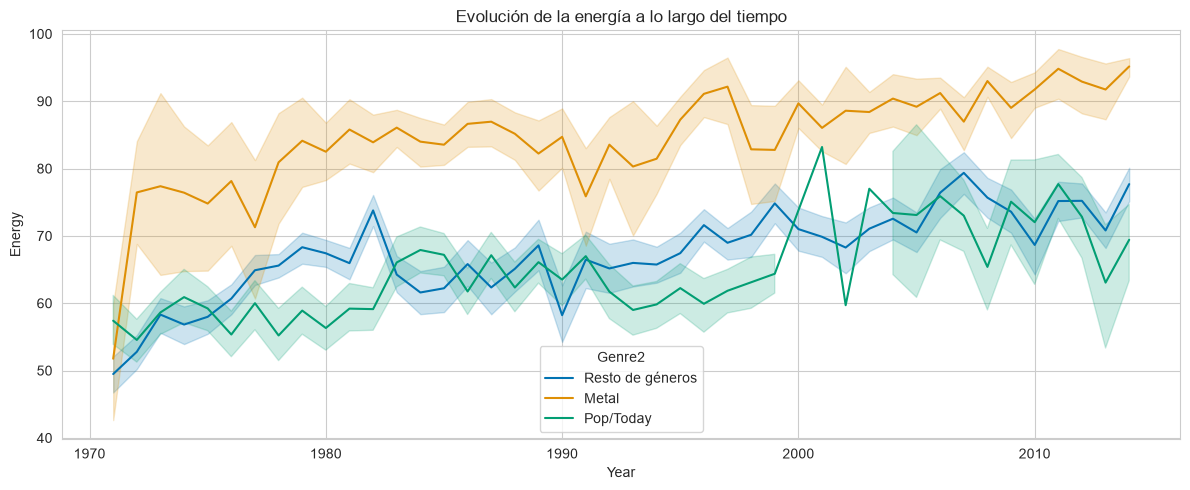

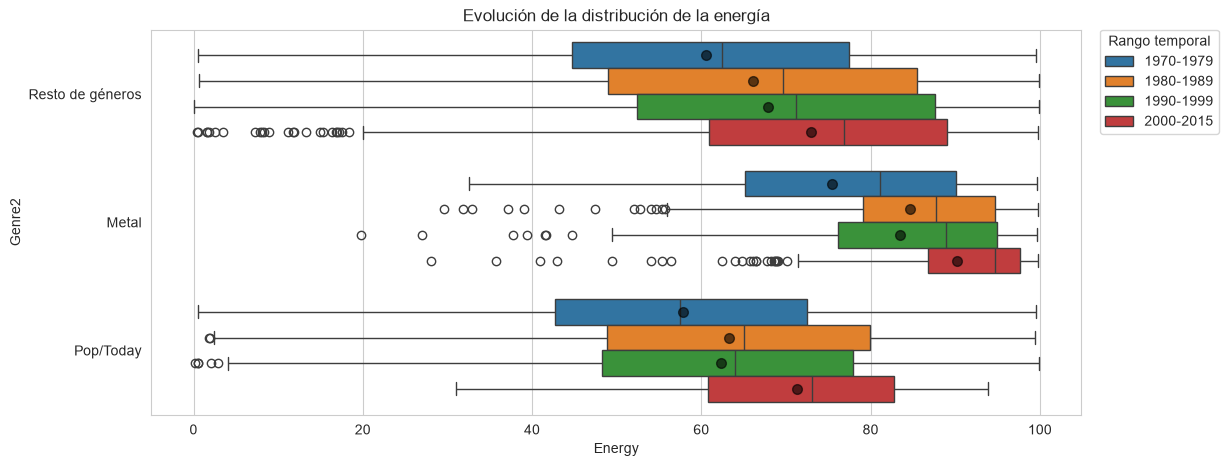

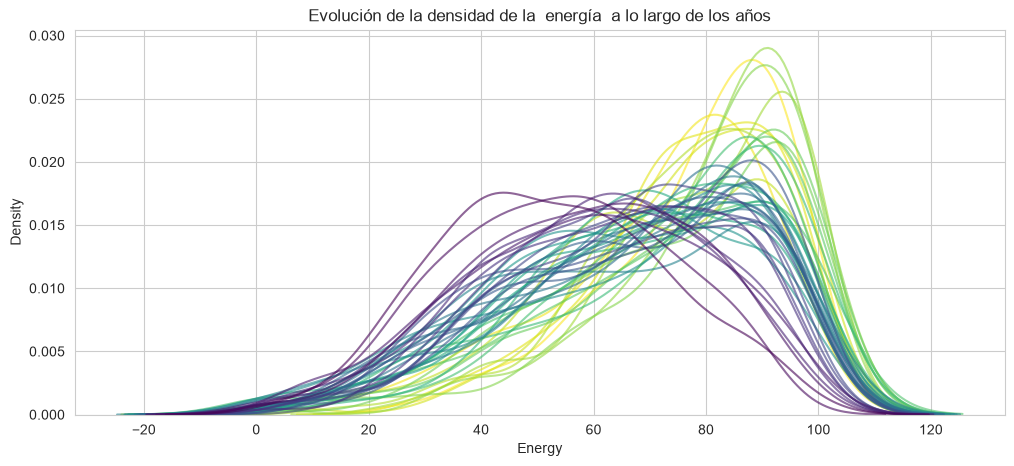

In [72]:
graflin(df,"Energy","Evolución de la energía a lo largo del tiempo")
cajatemp(df, "Energy", "Evolución de la distribución de la energía")
densi(df,"Energy","Evolución de la densidad de la  energía  a lo largo de los años")

# ¿Qué hace que una canción sea popular?

Para analizar esta relación, volvemos a utilizar la correlación de Spearman. Calculamos, para cada género musical, las correlaciones entre los distintos atributos musicales y la popularidad.

Por último, seleccionamos únicamente las correlaciones cuyo valor *p* es inferior a 0,01 y las representamos mediante un gráfico de barras.

In [73]:
def popugen(df, x):

    resultados = []

    for genero, subset in df.groupby("Genre"):
        r, p = spearmanr(subset[x], subset["Popularity"])

        if p < 0.01:
            resultados.append((genero, r, p))

    corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
    corr_df = corr_df.sort_values("R", ascending=False)

    plt.figure(figsize=(11, 4))

    sns.barplot(
        data=corr_df,
        x="R",
        y="Género",
        hue="R",
        palette="RdYlGn",
        hue_norm=(-1, 1),
        dodge=False,
        legend=False
    )

    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlim(-1, 1)
    plt.title(f"Correlación entre  popularidad y {x}  por género (p < 0.01)")
    plt.tight_layout()
    plt.xlabel("Correlación Spearman")
    plt.show()
    return


## Relación entre los atributos musicales y la popularidad

Si tenemos en cuenta la variable año, observamos que, cuanto más reciente es una canción, mayor tiende a ser su popularidad en los géneros Rock alternativo, Gospel, Rap, Country, R&B, Reggae, Punk, Metal y Pop, ordenados de mayor a menor intensidad de la correlación. En el caso del Rock, se observa la tendencia contraria: cuanto más antigua es una canción, mayor tiende a ser su popularidad.

En cuanto a la positividad percibida (*valence*), encontramos correlaciones positivas con la popularidad en EDM, Metal y Punk. Por el contrario, en Rock alternativo y Gospel la correlación es negativa. Resulta llamativo que Metal y EDM presenten niveles bajos de *valence*. En estos géneros, los resultados sugieren que las canciones con valores de positividad ligeramente superiores a los habituales tienden a ser más populares.

También encontramos correlaciones positivas entre energía musical (*energy*) y popularidad en Country, Reggae, Rock alternativo y Pop. Por el contrario, en Funk y EDM la correlación es negativa. Este último caso resulta especialmente llamativo, ya que el EDM presenta niveles elevados de energía musical.

En cuanto a la acusticidad (*acousticness*), encontramos otro fenómeno interesante. En Funk y EDM, cuanto mayor es la acusticidad de una canción, mayor tiende a ser su popularidad. Este resultado llama la atención, especialmente en el caso del EDM, uno de los géneros menos acústicos del conjunto de datos. Por el contrario, en Pop, Rock alternativo, Country, Blues y Gospel observamos correlaciones negativas entre acusticidad y popularidad. Esta relación resulta especialmente interesante en Blues y Gospel, cuyos niveles de acusticidad son moderados.

El penúltimo atributo que analizaremos es la capacidad de baile (*danceability*). En este caso, únicamente se han detectado correlaciones positivas con la popularidad. Los géneros en los que la asociación resulta estadísticamente significativa son Música actual, Jazz, Metal, Punk y EDM. Destacan los casos del Metal y el Punk, que en el análisis de medianas se situaban entre los géneros con menor capacidad de baile.

El último atributo que analizaremos es la instrumentalidad (*instrumentalness*). En este caso, se han encontrado correlaciones negativas entre esta característica y la popularidad en varios géneros. Ordenados de mayor a menor intensidad, son: Jazz, EDM, Metal, Rock alternativo, Disco, Punk y Pop.

Si volvemos a observar las medianas de instrumentalidad, expresadas en una escala de 0 a 100, comprobamos que solo dos géneros presentan valores superiores a 1: EDM y, especialmente, Jazz. Por tanto, los resultados sugieren que, dentro del Jazz, las canciones con menor instrumentalidad tienden a ser más populares.

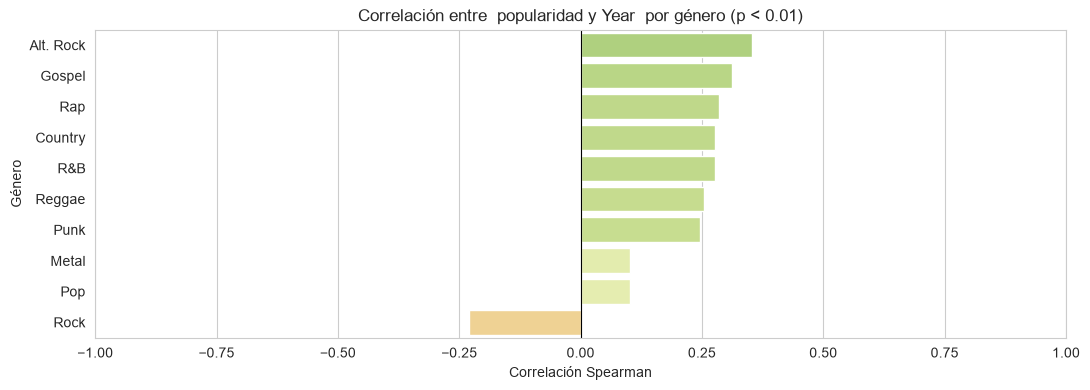

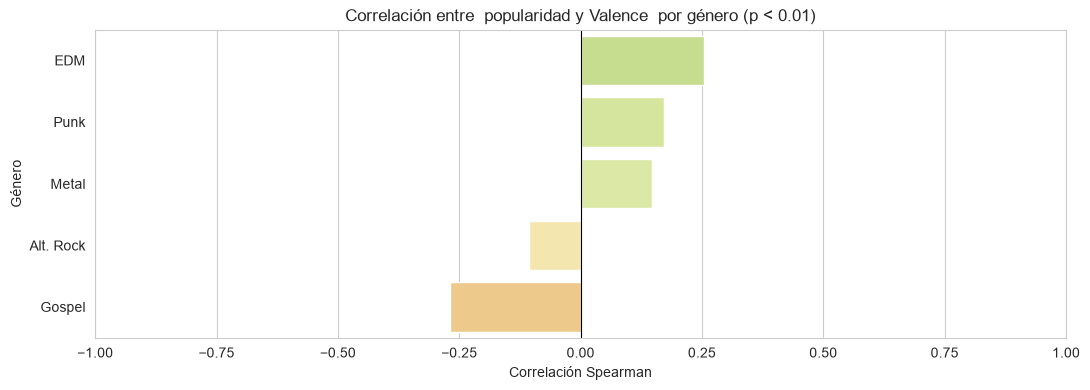

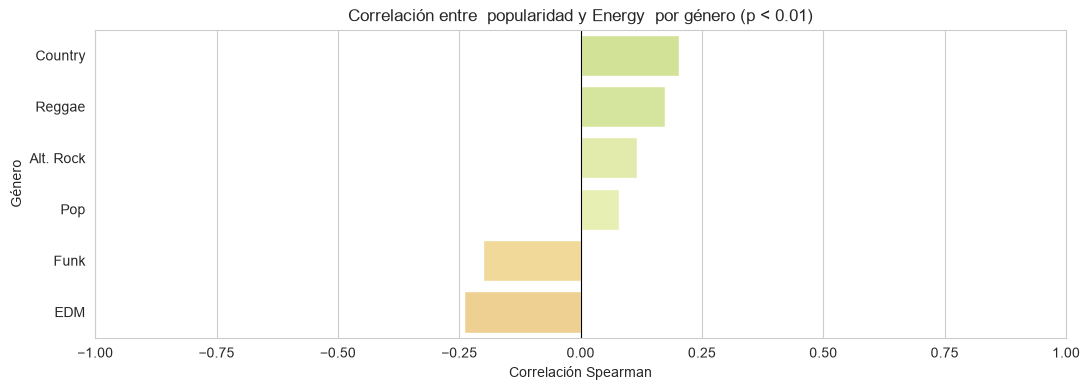

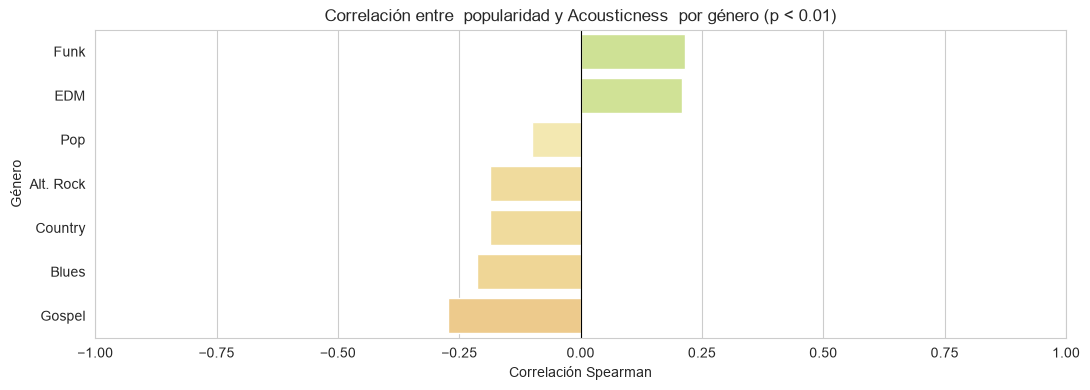

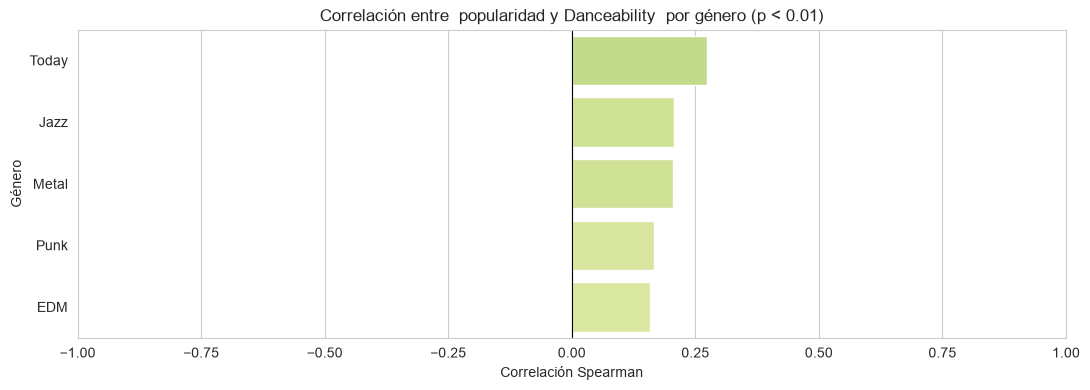

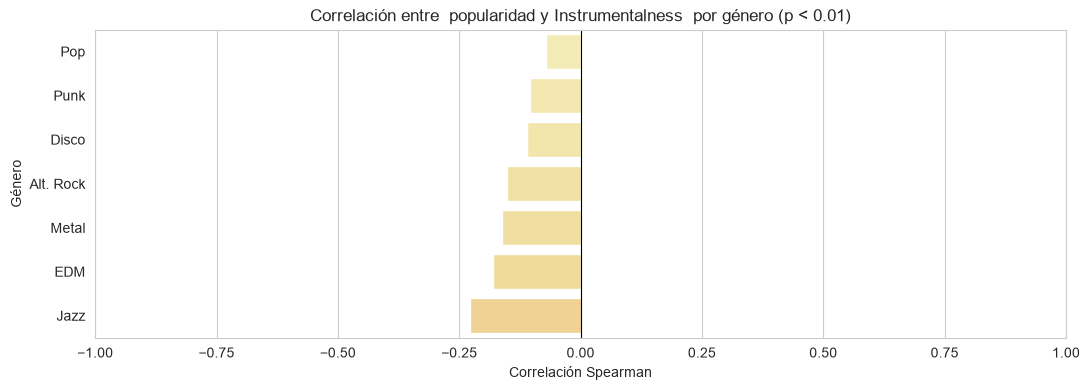

In [74]:
popugen(df,"Year")
popugen(df,"Valence")
popugen(df,"Energy")
popugen(df,"Acousticness")
popugen(df,"Danceability")
popugen(df,"Instrumentalness")


# Conclusiones

El análisis no muestra diferencias relevantes en los atributos musicales en función de la tonalidad o el modo de las canciones. Por tanto, los resultados respaldan la hipótesis de que estas variables no tienen una influencia significativa en los atributos analizados.

En cambio, los resultados sugieren que el compás sí puede estar relacionado con algunos de estos atributos. Por ello, no podemos descartar la hipótesis de que el compás ejerza cierta influencia, aunque sería necesario profundizar en esta relación para determinar su alcance.

El análisis también apunta a una evolución temporal: el volumen percibido y la energía musical han aumentado, mientras que la positividad percibida ha disminuido a lo largo del periodo estudiado.

Asimismo, los resultados sugieren que cada género presenta dinámicas propias y que estas pueden variar a lo largo del tiempo. No obstante, esta hipótesis requiere un estudio más profundo que permita contextualizar las diferencias observadas y contrastarlas con información histórica y sociocultural.

Por último, el análisis de popularidad apunta a que, en determinados géneros, las canciones que se alejan de los valores habituales de algunos atributos pueden alcanzar una mayor popularidad. Esta posibilidad resulta interesante, aunque las correlaciones observadas no permiten establecer una relación causal.